In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Menampilkan seluruh kolom saat diperlukan
pd.set_option("display.max_columns", None)

In [10]:
# Jika nama file berbeda, sesuaikan nama file di bawah ini
df = pd.read_csv("StudentPerformanceFactors.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [11]:
print("Informasi dataset:")
df.info()

print("\nStatistik kolom numerik:")
display(df.describe())

print("\nJumlah nilai kosong tiap kolom:")
display(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



Jumlah nilai kosong tiap kolom:


Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


Jumlah data duplikat: 0


In [12]:
# Membuat salinan agar data asli tidak berubah
data = df.copy()

# Menghapus baris duplikat jika ada
data = data.drop_duplicates()

# Pastikan target tersedia dan berbentuk numerik
data["Exam_Score"] = pd.to_numeric(data["Exam_Score"], errors="coerce")
data = data.dropna(subset=["Exam_Score"])

print("Ukuran data setelah pemeriksaan awal:", data.shape)
print("Jumlah nilai kosong per kolom setelah pemeriksaan target:")
display(data.isnull().sum())

Ukuran data setelah pemeriksaan awal: (6607, 20)
Jumlah nilai kosong per kolom setelah pemeriksaan target:


Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

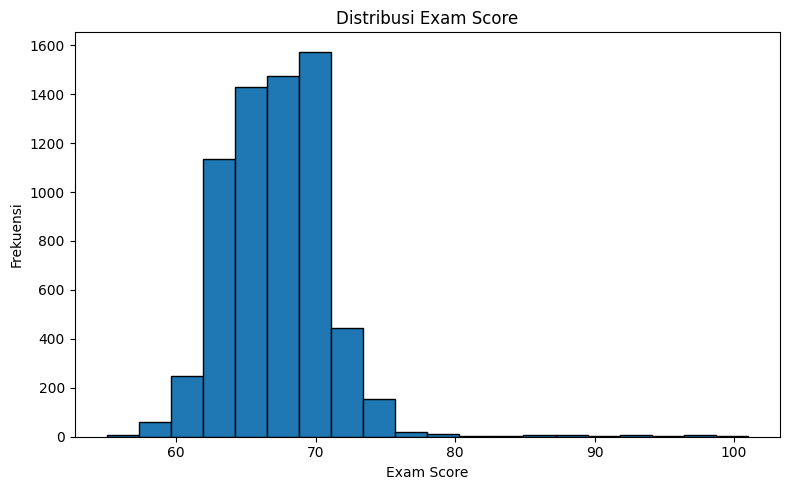

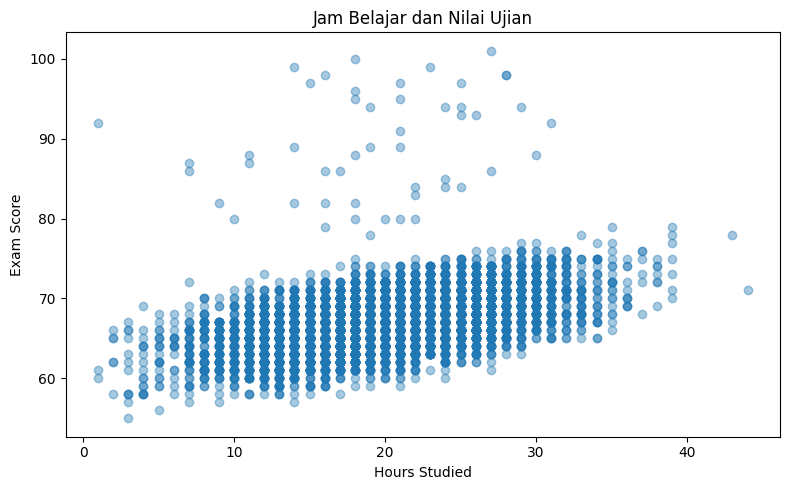

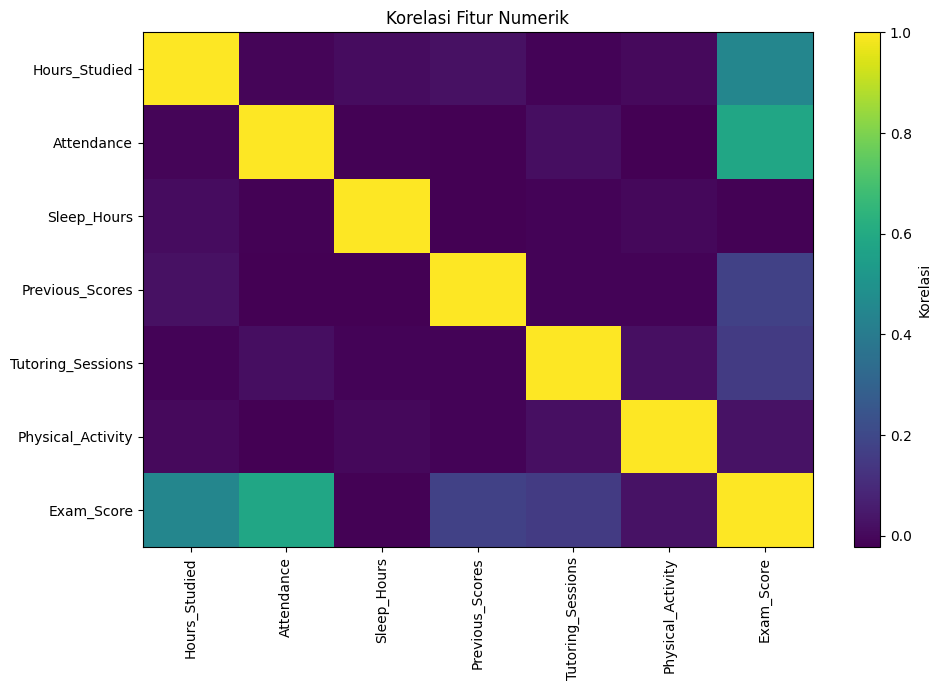

In [13]:
# Distribusi nilai ujian
plt.figure(figsize=(8, 5))
plt.hist(data["Exam_Score"], bins=20, edgecolor="black")
plt.title("Distribusi Exam Score")
plt.xlabel("Exam Score")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# Hubungan jam belajar dengan nilai ujian
plt.figure(figsize=(8, 5))
plt.scatter(data["Hours_Studied"], data["Exam_Score"], alpha=0.4)
plt.title("Jam Belajar dan Nilai Ujian")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show()

# Korelasi antarfitur numerik
numeric_data = data.select_dtypes(include=np.number)
corr = numeric_data.corr(numeric_only=True)
plt.figure(figsize=(10, 7))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Korelasi")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()

In [14]:
# Exam_Score menjadi target yang akan diprediksi
X = data.drop(columns=["Exam_Score"])
y = data["Exam_Score"]

# Memisahkan data training 80% dan testing 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Jumlah seluruh data:", len(data))
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Jumlah seluruh data: 6607
X_train: (5285, 19)
X_test : (1322, 19)
y_train: (5285,)
y_test : (1322,)


In [15]:
# Memisahkan kolom numerik dan kategorikal
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Kolom numerik: nilai kosong diisi median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Kolom kategori: nilai kosong diisi modus, lalu diubah menjadi angka
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing untuk kedua jenis kolom
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

Fitur numerik: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Fitur kategorikal: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [16]:
models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=8),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, max_depth=12, n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    # Dummy tidak membutuhkan preprocessing fitur, tetapi pipeline tetap digunakan
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })
    trained_models[name] = pipeline

comparison = pd.DataFrame(results).sort_values(by="RMSE")
display(comparison)

,Model,MAE,MSE,RMSE,R2 Score
1,Linear Regression,0.452392,3.256020,1.804445,0.769650
3,Random Forest,1.098847,4.698843,2.167681,0.667576
2,Decision Tree,1.561985,7.656998,2.767128,0.458298
0,Dummy Regressor,2.823490,14.145592,3.761063,-0.000744


In [17]:
best_name = comparison.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Model dengan RMSE terkecil:", best_name)
print("MAE :", mean_absolute_error(y_test, best_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, best_predictions)))
print("R2  :", r2_score(y_test, best_predictions))

# Membandingkan nilai aktual dan hasil prediksi pada 10 data pertama
hasil_prediksi = pd.DataFrame({
    "Nilai Aktual": y_test.iloc[:10].to_numpy(),
    "Hasil Prediksi": best_predictions[:10]
})
display(hasil_prediksi)

Model dengan RMSE terkecil: Linear Regression
MAE : 0.4523920089625977
RMSE: 1.804444509272284
R2  : 0.7696495724907312


,Nilai Aktual,Hasil Prediksi
0,65,64.526283
1,65,65.265114
2,71,71.531263
3,64,64.277481
4,66,66.521653
5,66,66.612463
6,72,72.470949
7,66,66.498269
8,70,69.986045
9,70,70.133271


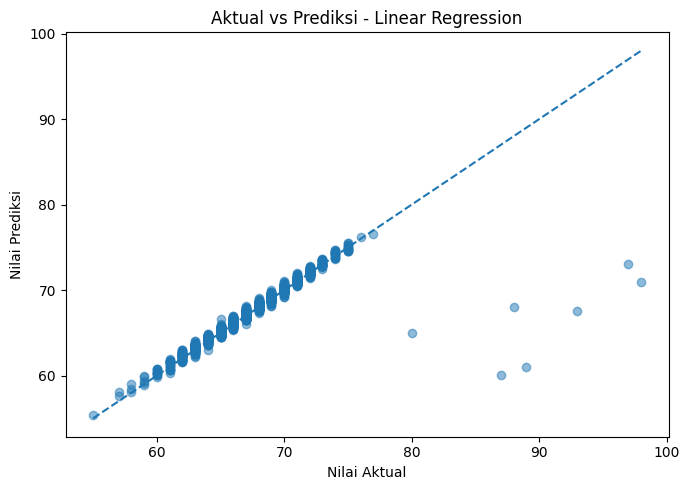

In [18]:
# Grafik aktual vs prediksi untuk model terbaik
plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_predictions, alpha=0.5)
min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title(f"Aktual vs Prediksi - {best_name}")
plt.xlabel("Nilai Aktual")
plt.ylabel("Nilai Prediksi")
plt.tight_layout()
plt.show()

In [21]:

# Import library untuk menyimpan model
import joblib
import pandas as pd

print("Library berhasil diimpor.")

# Menyimpan model terbaik yang sudah dilatih, termasuk preprocessing
model_path = "model_terbaik_exam_score.joblib"
joblib.dump(best_model, model_path)
print(f"Model terbaik ({best_name}) berhasil disimpan ke: {model_path}")

# Menyimpan tabel perbandingan seluruh model
comparison.to_csv("hasil_perbandingan_model.csv", index=False)
print("Tabel perbandingan model disimpan ke: hasil_perbandingan_model.csv")

# Menyimpan hasil prediksi data testing
hasil_semua_prediksi = pd.DataFrame({
    "Nilai_Aktual": y_test.to_numpy(),
    "Nilai_Prediksi": best_predictions
})
hasil_semua_prediksi.to_csv("hasil_prediksi_model_terbaik.csv", index=False)
print("Hasil prediksi disimpan ke: hasil_prediksi_model_terbaik.csv")

Library berhasil diimpor.
Model terbaik (Linear Regression) berhasil disimpan ke: model_terbaik_exam_score.joblib
Tabel perbandingan model disimpan ke: hasil_perbandingan_model.csv
Hasil prediksi disimpan ke: hasil_prediksi_model_terbaik.csv
